# E-Commerce Sales Intelligence — Exploratory Data Analysis

## Visualization and Business Insights

This notebook explores the cleaned e-commerce transaction data using
Matplotlib, Seaborn, and Plotly.

The visualizations are used to understand sales trends, product
performance, customer behavior, cancellations, and geographical patterns.

### Visualization Libraries

- Matplotlib — basic and customizable statistical visualizations
- Seaborn — statistical and categorical visualizations
- Plotly — interactive visualizations

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import plotly.express as px

In [2]:
df=pd.read_csv(r"../data/processed/online_retail_cleaned.csv")


In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,Day,DayName,Hour,IsCancelled
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009,12,December,1,Tuesday,7,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009,12,December,1,Tuesday,7,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009,12,December,1,Tuesday,7,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009,12,December,1,Tuesday,7,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009,12,December,1,Tuesday,7,False


In [4]:
df.shape

(1027015, 16)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1027015 entries, 0 to 1027014
Data columns (total 16 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   InvoiceNo    1027015 non-null  str    
 1   StockCode    1027015 non-null  str    
 2   Description  1027015 non-null  str    
 3   Quantity     1027015 non-null  int64  
 4   InvoiceDate  1027015 non-null  str    
 5   UnitPrice    1027015 non-null  float64
 6   CustomerID   797813 non-null   float64
 7   Country      1027015 non-null  str    
 8   Revenue      1027015 non-null  float64
 9   Year         1027015 non-null  int64  
 10  Month        1027015 non-null  int64  
 11  MonthName    1027015 non-null  str    
 12  Day          1027015 non-null  int64  
 13  DayName      1027015 non-null  str    
 14  Hour         1027015 non-null  int64  
 15  IsCancelled  1027015 non-null  bool   
dtypes: bool(1), float64(3), int64(5), str(7)
memory usage: 200.4 MB


In [6]:
df["InvoiceDate"]=pd.to_datetime(df["InvoiceDate"])

In [7]:
df["InvoiceDate"].dtypes

dtype('<M8[us]')

In [8]:
df["InvoiceDate"]

0         2009-12-01 07:45:00
1         2009-12-01 07:45:00
2         2009-12-01 07:45:00
3         2009-12-01 07:45:00
4         2009-12-01 07:45:00
                  ...        
1027010   2011-12-09 12:50:00
1027011   2011-12-09 12:50:00
1027012   2011-12-09 12:50:00
1027013   2011-12-09 12:50:00
1027014   2011-12-09 12:50:00
Name: InvoiceDate, Length: 1027015, dtype: datetime64[us]

## Monthly Revenue Trend

Monthly revenue is analyzed to understand how sales changed over time.
This helps identify growth patterns, seasonal trends, and periods of
higher or lower business activity.

In [9]:
# Keep the actual InvoiceDate column as datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Create a month-year series for aggregation and keep the expected variable name
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
yearmonth = df["YearMonth"]

In [10]:
revenue_by_yearmonth = df.groupby("YearMonth")["Revenue"].sum()
revenue_by_yearmonth

YearMonth
2009-12     796648.500
2010-01     622479.502
2010-02     531265.366
2010-03     763247.241
2010-04     641521.052
2010-05     613270.720
2010-06     677073.870
2010-07     617365.480
2010-08     654774.390
2010-09     851105.961
2010-10    1080611.480
2010-11    1416697.202
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722079.250
2011-06     689977.230
2011-07     680156.991
2011-08     703510.580
2011-09    1017596.682
2011-10    1069368.230
2011-11    1455608.800
2011-12     432719.060
Name: Revenue, dtype: float64

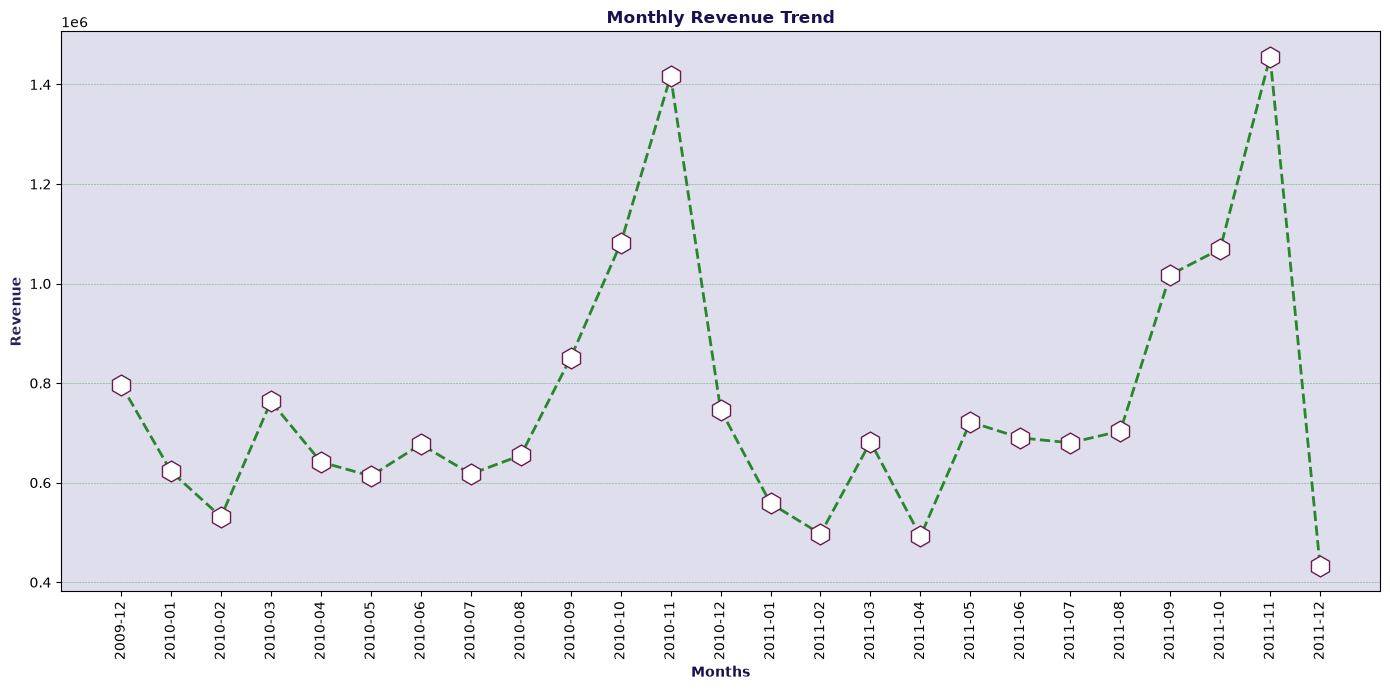

In [77]:
plt.figure(figsize=(14, 7))
plt.plot(revenue_by_yearmonth.index,revenue_by_yearmonth.values, 
        marker="h",
        color="#27872AFF", 
        mec="#6C1A4A", mfc="white", ms=15,
        linestyle="--",
        linewidth=2)

ax=plt.gca()  
ax.set_facecolor("#DEDEED")

plt.xticks(rotation=90)
plt.title("Monthly Revenue Trend", color="#18104F", fontweight="bold")
plt.xlabel("Months", color="#18104F", fontweight="bold")
plt.ylabel("Revenue", color="#28205C", fontweight="bold")

plt.grid(axis="y",linestyle="--",linewidth="0.4",color="green",alpha=0.5)

plt.tight_layout()

plt.show()

## Top 10 Countries by Revenue

This analysis compares the total revenue generated by the top 10 countries.

It helps identify the major geographical markets contributing to overall sales.


In [12]:
df["Country"].value_counts()

Country
United Kingdom          942327
EIRE                     17662
Germany                  17331
France                   14024
Netherlands               5132
Spain                     3753
Switzerland               3174
Belgium                   3109
Portugal                  2528
Australia                 1887
Channel Islands           1646
Italy                     1507
Sweden                    1362
Norway                    1307
Cyprus                    1157
Finland                   1049
Austria                    938
Denmark                    797
Unspecified                752
Greece                     663
Japan                      565
USA                        535
Poland                     527
United Arab Emirates       500
Israel                     368
Hong Kong                  360
Singapore                  346
Malta                      299
Canada                     228
Iceland                    222
RSA                        168
Lithuania                  154


In [13]:
country_revenue=df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
country_revenue

Country
United Kingdom    1.614418e+07
EIRE              6.099538e+05
Netherlands       5.483307e+05
Germany           4.119592e+05
France            3.217334e+05
Australia         1.664444e+05
Switzerland       9.940306e+04
Spain             9.101344e+04
Sweden            8.777552e+04
Denmark           6.445959e+04
Name: Revenue, dtype: float64

In [14]:
fig =px.bar(country_revenue,
    x=country_revenue.values,
    y=country_revenue.index,
    orientation="h"
)

fig.update_layout(title="Top 10 Countries by Revenue",title_font=dict(size=20, color="#18104F"),
    xaxis_title="Revenue",
    yaxis_title="Country",
    height=550,
    template="plotly_white"
)

fig.update_traces(
    marker_color="#379A9E",
    opacity=0.85
)

fig.show()





## Top 10 Products by Revenue

This analysis identifies the products that generate the highest total revenue.
It helps understand which products contribute most to overall business sales.




In [15]:
df["Description"].value_counts()

Description
WHITE HANGING HEART T-LIGHT HOLDER     5744
mailout                                5017
REGENCY CAKESTAND 3 TIER               4291
JUMBO BAG RED WHITE SPOTTY             4126
PACK OF 72 RETRO SPOT CAKE CASES       3209
                                       ... 
FLOWER SHOP DESIGN MUG                    1
SET OF 6 EASTER RAINBOW CHICKS            1
SET 10 CARD CHRISTMAS STAMPS 16963        1
SET 10 CARDS SNOWY ROBIN 17099            1
SET 10 CARDS SWIRLY XMAS TREE 17104       1
Name: count, Length: 4734, dtype: int64

In [16]:
des_rev=df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10).reset_index()
des_rev

,Description,Revenue
0,REGENCY CAKESTAND 3 TIER,314045.02
1,DOTCOM POSTAGE,309844.10
2,WHITE HANGING HEART T-LIGHT HOLDER,251781.63
3,JUMBO BAG RED WHITE SPOTTY,178400.52
4,mailout,172762.72
5,PARTY BUNTING,147079.73
6,ASSORTED COLOUR BIRD ORNAMENT,128550.42
7,PAPER CHAIN KIT 50'S CHRISTMAS,116298.59
8,POSTAGE,110430.41
9,CHILLI LIGHTS,79905.13


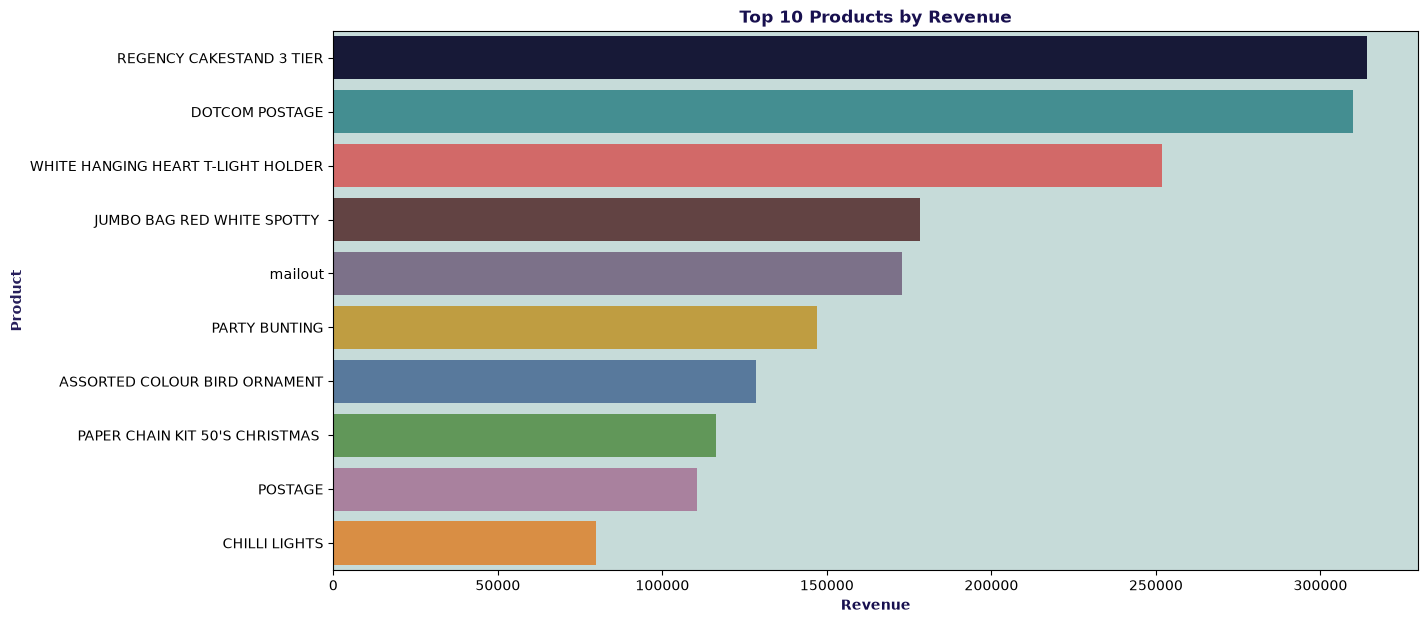

In [17]:
plt.figure(figsize=(14,7))
sns.barplot(x=des_rev["Revenue"], y=des_rev["Description"], 
        orient="h", 
        palette=[
            "#12143C",
            "#379A9E",
            "#E45756",
            "#673E3E",
            "#7B6D8D",
            "#D4A72C",
            "#4C78A8",
            "#59A14F",
            "#B07AA1",
            "#F28E2B"
    ],
    hue=des_rev["Description"],
    legend=False)

ax=plt.gca()   #get current axes
ax.set_facecolor("#C6DBD9")


plt.title("Top 10 Products by Revenue", color="#18104F", fontweight="bold")
plt.xlabel("Revenue", color="#18104F", fontweight="bold")
plt.ylabel("Product", color="#28205C", fontweight="bold")
plt.show()

## Customer Purchase Analysis

This analysis examines customer purchasing behavior by comparing the total revenue generated by individual customers.

It helps identify high-value customers and understand customer-level sales contribution.


In [18]:
df["CustomerID"].isna().sum()

np.int64(229202)

In [19]:
temp_df = df.dropna(subset=["CustomerID"]).copy()
temp_df = temp_df[~temp_df["IsCancelled"]]
temp_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,Day,DayName,Hour,IsCancelled,YearMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40,2009,12,December,1,Tuesday,7,False,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00,2009,12,December,1,Tuesday,7,False,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00,2009,12,December,1,Tuesday,7,False,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80,2009,12,December,1,Tuesday,7,False,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00,2009,12,December,1,Tuesday,7,False,2009-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1027010,581587,22899,CHILDRENS APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011,12,December,9,Friday,12,False,2011-12
1027011,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,December,9,Friday,12,False,2011-12
1027012,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,December,9,Friday,12,False,2011-12
1027013,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85,2011,12,December,9,Friday,12,False,2011-12


In [20]:
cust_rev=temp_df.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(10).reset_index()
cust_rev

,CustomerID,Revenue
0,18102.0,580987.04
1,14646.0,528602.52
2,14156.0,313437.62
3,14911.0,291420.81
4,17450.0,244784.25
5,13694.0,195640.69
6,17511.0,172132.87
7,16446.0,168472.50
8,16684.0,147142.77
9,12415.0,144458.37


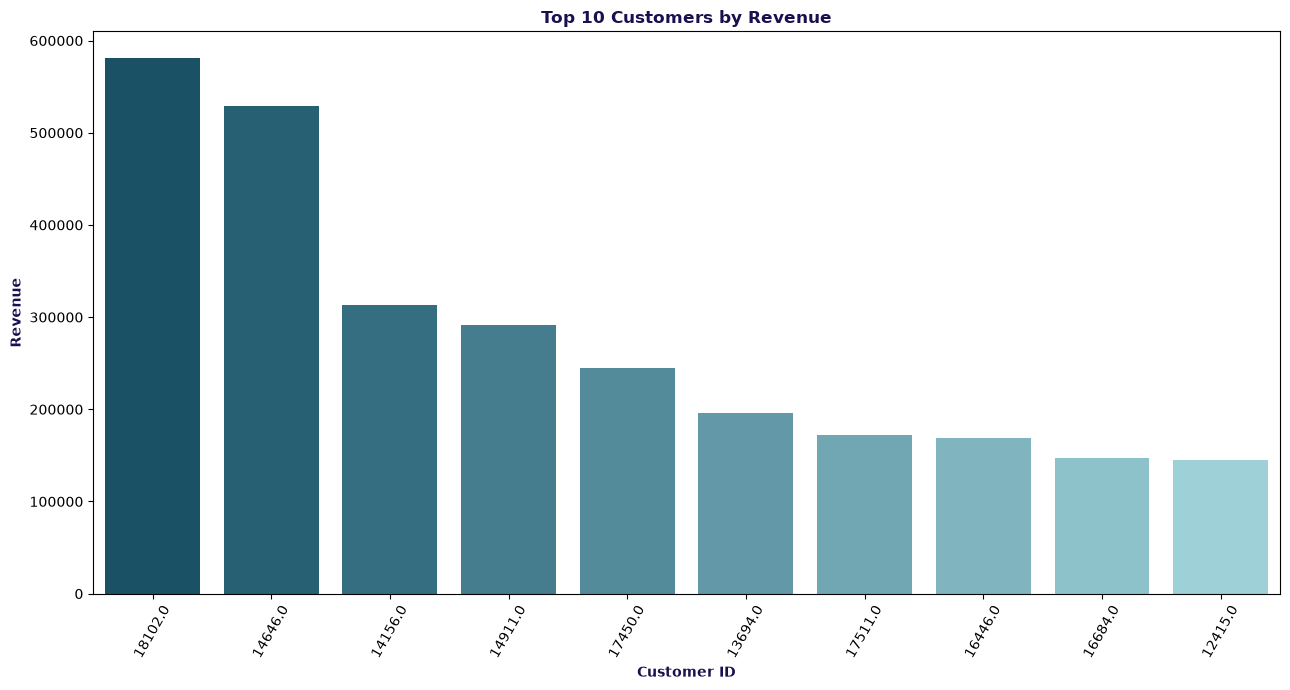

In [78]:
plt.figure(figsize=(13,7))
sns.barplot(cust_rev, x=cust_rev["CustomerID"].astype(str), y=cust_rev["Revenue"], 
            palette=[
                "#0D5772",
                "#1B6680",
                "#2A748D",
                "#39839A",
                "#4891A6",
                "#579FB2",
                "#66ADBE",
                "#75BBC9",
                "#84C9D5",
                "#93D7E1"
    ],
    hue=cust_rev["CustomerID"].astype(str),
    legend=False)

plt.title("Top 10 Customers by Revenue",color="#18104F",fontweight="bold")
plt.xticks(rotation=60)
plt.xlabel("Customer ID", color="#18104F",fontweight="bold")
plt.ylabel("Revenue",color="#18104F",fontweight="bold")
plt.tight_layout()
plt.show()



## Cancellation Analysis

This analysis compares cancelled and completed transactions to understand the impact of cancellations on overall transaction activity.

It helps identify how frequently cancellations occur in the dataset.


In [22]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Year', 'Month',
       'MonthName', 'Day', 'DayName', 'Hour', 'IsCancelled', 'YearMonth'],
      dtype='str')

In [23]:
c_IsC=df.groupby("IsCancelled").size()
c_IsC

IsCancelled
False    1007911
True       19104
dtype: int64

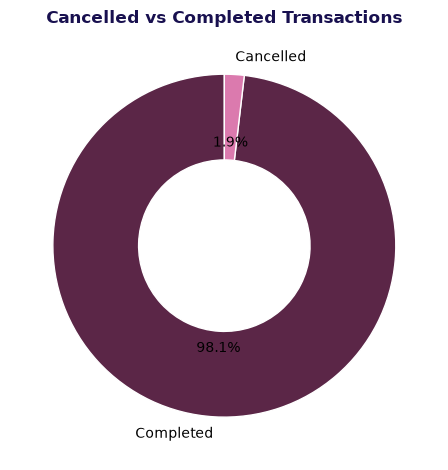

In [24]:
status_counts = c_IsC

labels = ["Completed", "Cancelled"]
sizes = [status_counts.get(False, 0), status_counts.get(True, 0)]
colors = ["#5B2647","#DB7AAE"]

plt.pie(
    sizes,
    labels=labels,
    colors=colors,
    startangle=90,
    autopct="%1.1f%%",
    wedgeprops={"width":0.5,"edgecolor": "white"}
)
plt.title("Cancelled vs Completed Transactions", color="#18104F",fontweight="bold")

plt.tight_layout()
plt.show()

## Sales by Hour

This analysis examines how revenue varies across different hours of the day.

It helps identify the time periods when sales activity is highest and provides insights into customer purchasing patterns.


In [25]:
df["Hour"].value_counts()

Hour
12    153574
13    145084
14    134908
15    129876
11    116754
16     90372
10     90240
9      66826
17     55580
18     16071
8      15819
19      8697
20      2055
7       1117
6         41
21         1
Name: count, dtype: int64

In [26]:
ho_rev=df.groupby("Hour")["Revenue"].sum().reset_index()
ho_rev

,Hour,Revenue
0,6,-497.350
1,7,73474.220
2,8,520296.060
3,9,1518613.841
4,10,2409214.713
5,11,2349075.453
6,12,2708406.141
7,13,2391952.364
8,14,2210247.231
9,15,2138790.212


In [27]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=ho_rev["Hour"],
        y=ho_rev["Revenue"],
        name="Revenue",
        marker_color="#6CA88E"
    )
)

fig.add_trace(
    go.Scatter(
        x=ho_rev["Hour"],
        y=ho_rev["Revenue"],
        mode="lines+markers",
        name="Revenue Trend",
         line=dict(
            color="#E6A8A8",
            width=3
        ),
        marker=dict(
            color="#533434",
            size=10
        )
    )
)

fig.update_layout(
    title="Revenue by Hour",
    xaxis_title="Hour",
    yaxis_title="Revenue"

)




fig.show()

## Revenue by Day of Week

This analysis compares revenue across different days of the week.

It helps identify which days generate higher sales activity and provides insight into weekly purchasing patterns.


In [28]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["DayName"] = pd.Categorical(df["DayName"], categories=day_order, ordered=True)

In [29]:
week=df.groupby("DayName")["Revenue"].sum().reset_index()
week

,DayName,Revenue
0,Monday,3317210.356
1,Tuesday,3724295.592
2,Wednesday,3316834.003
3,Thursday,3940111.262
4,Friday,2926385.363
5,Saturday,9803.050
6,Sunday,1779018.362


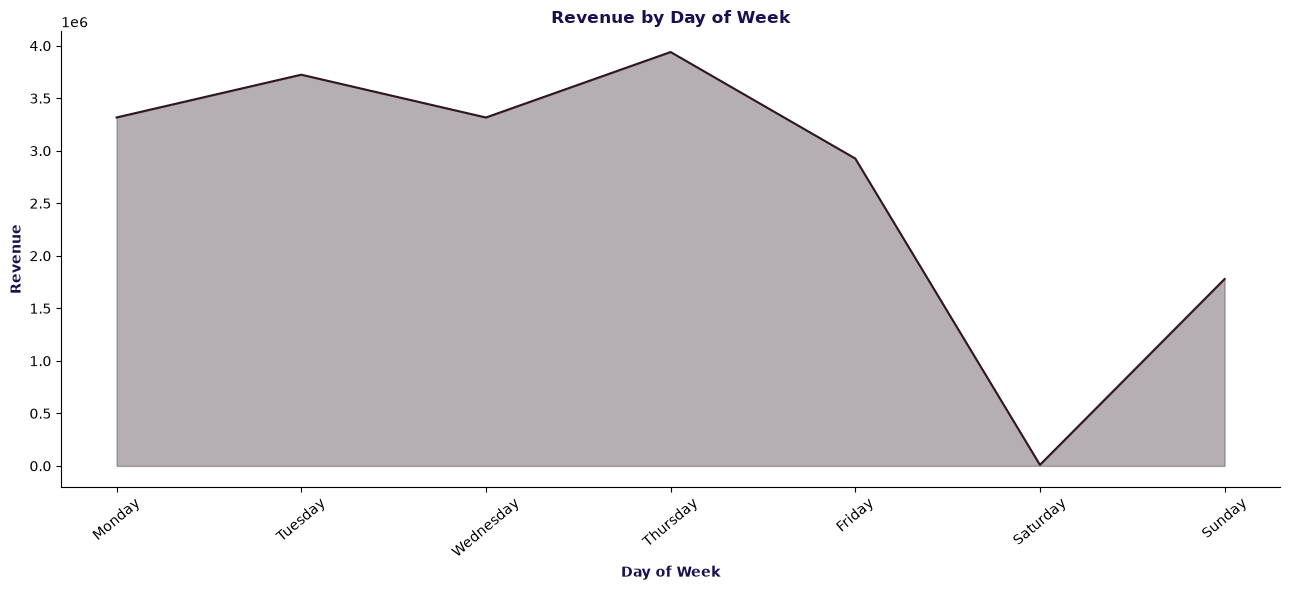

In [84]:
plt.figure(figsize=(13,6))
ax=plt.axes()
sns.lineplot(x=week["DayName"],y=week["Revenue"], color="#2F1622")
plt.fill_between(x=week["DayName"],y1=week["Revenue"], alpha=0.4, color="#483741")

ax.spines[["top","right"]].set_visible(False)
plt.title("Revenue by Day of Week", color="#18104F",fontweight="bold")
plt.xticks(rotation=40)
plt.xlabel("Day of Week", color="#18104F",fontweight="bold")
plt.ylabel("Revenue", color="#18104F",fontweight="bold")
plt.tight_layout()
plt.show()


## Top 10 Products by Quantity Sold

This analysis identifies the products with the highest quantity sold.

It helps understand which products have the highest sales volume and provides insight into product demand.


In [31]:
prod_Qty=df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10).reset_index()
prod_Qty

,Description,Quantity
0,WORLD WAR 2 GLIDERS ASSTD DESIGNS,104435
1,JUMBO BAG RED WHITE SPOTTY,95544
2,PACK OF 72 RETRO SPOT CAKE CASES,93774
3,WHITE HANGING HEART T-LIGHT HOLDER,91082
4,"POPCORN HOLDER , SMALL",87695
5,ASSORTED COLOUR BIRD ORNAMENT,79571
6,BROCADE RING PURSE,69629
7,PACK OF 60 PINK PAISLEY CAKE CASES,55842
8,60 TEATIME FAIRY CAKE CASES,53678
9,mailout,49585


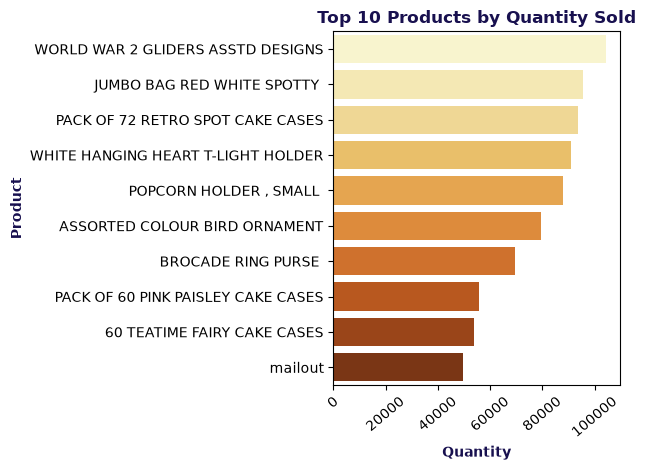

In [32]:
sns.barplot(x=prod_Qty["Quantity"], y=prod_Qty["Description"], 
            orient="h", 
            palette="YlOrBr",
            hue=prod_Qty["Description"],
            legend=False)

plt.title("Top 10 Products by Quantity Sold", color="#18104F",fontweight="bold")
plt.xticks(rotation=40)
plt.xlabel("Quantity", color="#18104F",fontweight="bold")
plt.ylabel("Product", color="#18104F",fontweight="bold")
plt.tight_layout()

plt.show()

## Top 10 Products by Number of Transactions

This analysis identifies the products that appear in the highest number of transactions.

It helps understand which products are purchased most frequently, independent of the quantity sold or total revenue.


In [33]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Year', 'Month',
       'MonthName', 'Day', 'DayName', 'Hour', 'IsCancelled', 'YearMonth'],
      dtype='str')

In [34]:
trans_count=df.groupby("Description").size().sort_values(ascending=False).head(10)
trans_count

Description
WHITE HANGING HEART T-LIGHT HOLDER    5744
mailout                               5017
REGENCY CAKESTAND 3 TIER              4291
JUMBO BAG RED WHITE SPOTTY            4126
PACK OF 72 RETRO SPOT CAKE CASES      3209
LUNCH BAG RED SPOTTY                  3170
ASSORTED COLOUR BIRD ORNAMENT         2867
PARTY BUNTING                         2728
STRAWBERRY CERAMIC TRINKET BOX        2665
LUNCHBAG SUKI  DESIGN                 2468
dtype: int64

In [35]:
fig = px.bar(trans_count, x= trans_count.values, y=trans_count.index, 
            orientation="h",
            color=trans_count.index,
            color_discrete_sequence=[
                "#3C1A5B",
                "#51266F",
                "#673E8E",
                "#7E57A2",
                "#9575B8",
                "#AB8CC7",
                "#C1A3D6",
                "#D7BBE3",
                "#E3CDEB",
                "#EADCF0"
            ])

fig.update_layout(title="Top 10 Products by Number of Transactions",title_font=dict(size=20, color="#18104F"),
    xaxis_title="No of Orders",
    yaxis_title="Product",
    height=550,
    template="plotly_white"
)


fig.show()

## Yearly Revenue Trend

This analysis compares total revenue generated across different years.

It helps understand the overall yearly sales performance and changes in revenue over time.


In [36]:
yearly_Reven=df.groupby("Year")["Revenue"].sum().reset_index()
yearly_Reven

,Year,Revenue
0,2009,796648.500
1,2010,9216135.874
2,2011,9000873.614


In [37]:
fig = px.area(
    yearly_Reven,
    x="Year",
    y="Revenue",
    title="Yearly Revenue Trend",
    
)

fig.update_traces(
    fillcolor="#E3A9A9",
    line_color="#673E3E",
)

fig.show()

## Cancellation Rate by Year

This analysis compares the percentage of cancelled transactions across different years.

It helps understand whether the cancellation rate changed over time and provides insight into transaction quality and customer purchasing behavior.


In [38]:
df.groupby("Year").count()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,MonthName,Day,DayName,Hour,IsCancelled,YearMonth
Year,,,,,,,,,,,,,,,,
2009,44466,44466,44466,44466,44466,44466,31269,44466,44466,44466,44466,44466,44466,44466,44466,44466
2010,490131,490131,490131,490131,490131,490131,391332,490131,490131,490131,490131,490131,490131,490131,490131,490131
2011,492418,492418,492418,492418,492418,492418,375212,492418,492418,492418,492418,492418,492418,492418,492418,492418


In [39]:
tr_fal=df.groupby("Year")["IsCancelled" ].value_counts()
tr_fal

Year  IsCancelled
2009  False           43453
      True             1013
2010  False          480572
      True             9559
2011  False          483886
      True             8532
Name: count, dtype: int64

In [40]:
# tr_fal has a MultiIndex: (Year, IsCancelled)
# Get cancelled counts by year and divide by total transactions in that year
Cancellation_Rate = (
    tr_fal.xs(True, level="IsCancelled") /
    tr_fal.groupby(level="Year").sum()
) * 100 

In [41]:
Cancellation_Rate

Year
2009    2.278145
2010    1.950295
2011    1.732674
Name: count, dtype: float64

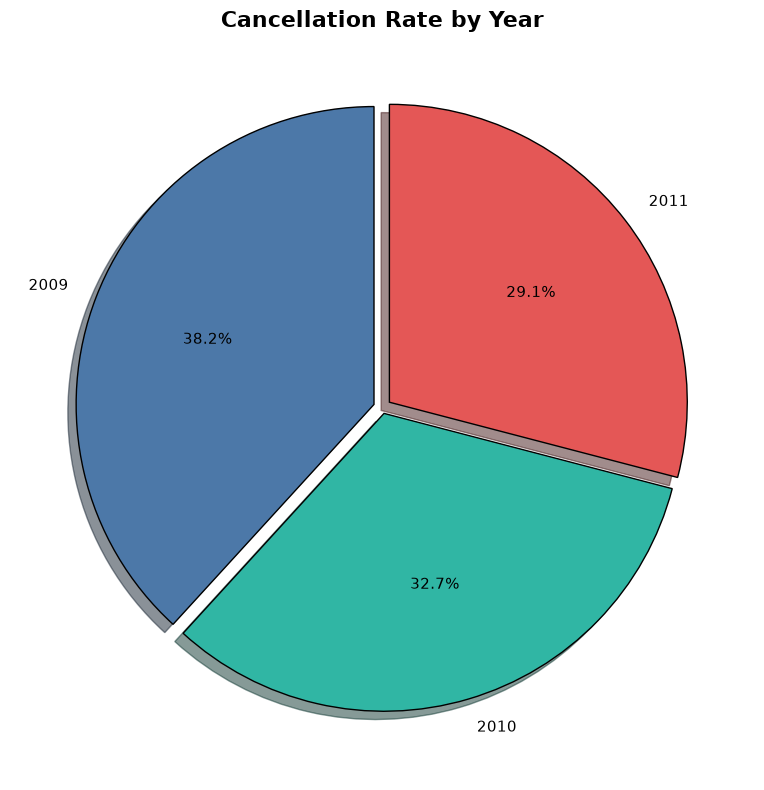

In [42]:
plt.figure(figsize=(8, 8))

colors = ["#4C78A8", "#30B6A4", "#E45756"]

plt.pie(
    Cancellation_Rate.values,
    labels=Cancellation_Rate.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={ "edgecolor": "black"},
    textprops={"fontsize": 11},
    shadow=True,
    explode=[0.03,0.02,0.03]
)

plt.title(
    "Cancellation Rate by Year",
    fontsize=16,
    fontweight="bold",
    
    
)

plt.tight_layout()
plt.show()

## Top 10 Customers by Number of Orders

This analysis identifies the customers who place the highest number of orders.

It helps understand customer purchase frequency and identify highly active customers.

In [43]:
customer_df = df[(df["CustomerID"].notna() & (~df["IsCancelled"]))]
customer_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,Day,DayName,Hour,IsCancelled,YearMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40,2009,12,December,1,Tuesday,7,False,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00,2009,12,December,1,Tuesday,7,False,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00,2009,12,December,1,Tuesday,7,False,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80,2009,12,December,1,Tuesday,7,False,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00,2009,12,December,1,Tuesday,7,False,2009-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1027010,581587,22899,CHILDRENS APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011,12,December,9,Friday,12,False,2011-12
1027011,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,December,9,Friday,12,False,2011-12
1027012,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,December,9,Friday,12,False,2011-12
1027013,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85,2011,12,December,9,Friday,12,False,2011-12


In [44]:
cust_value = customer_df.groupby(["CustomerID", "InvoiceNo"]).count()

cust_value

StockCode  Description  Quantity  InvoiceDate  \
CustomerID InvoiceNo                                                  
12346.0    491725             1            1         1            1   
           491742             1            1         1            1   
           491744             1            1         1            1   
           492718             1            1         1            1   
           492722             1            1         1            1   
...                         ...          ...       ...          ...   
18287.0    523290             2            2         2            2   
           534346            10           10        10           10   
           554065            29           29        29           29   
           570715            38           38        38           38   
           573167             3            3         3            3   

                      UnitPrice  Country  Revenue  Year  Month  MonthName  \
CustomerID InvoiceNo                                                        
12346.0    491725             1        1        1     1      1          1   
           491742             1        1        1     1      1          1   
           491744             1        1        1     1      1          1   
           492718             1        1        1     1      1          1   
           492722             1        1        1     1      1          1   
...                         ...      ...      ...   ...    ...        ...   
18287.0    523290             2        2        2     2      2          2   
           534346            10       10       10    10     10         10   
           554065            29       29       29    29     29         29   
           570715            38       38       38    38     38         38   
           573167             3        3        3     3      3          3   

                      Day  DayName  Hour  IsCancelled  YearMonth  
CustomerID InvoiceNo                                              
12346.0    491725       1        1     1            1          1  
           491742       1        1     1            1          1  
           491744       1        1     1            1          1  
           492718       1        1     1            1          1  
           492722       1        1     1            1          1  
...                   ...      ...   ...          ...        ...  
18287.0    523290       2        2     2            2          2  
           534346      10       10    10           10         10  
           554065      29       29    29           29         29  
           570715      38       38    38           38         38  
           573167       3        3     3            3          3  

[36969 rows x 15 columns]

In [45]:
customers_order = cust_value.groupby(level="CustomerID").size().sort_values(ascending=False).head(10)
customers_order

CustomerID
14911.0    398
12748.0    336
17841.0    211
15311.0    208
13089.0    203
14606.0    192
14156.0    156
17850.0    155
14646.0    151
18102.0    145
dtype: int64

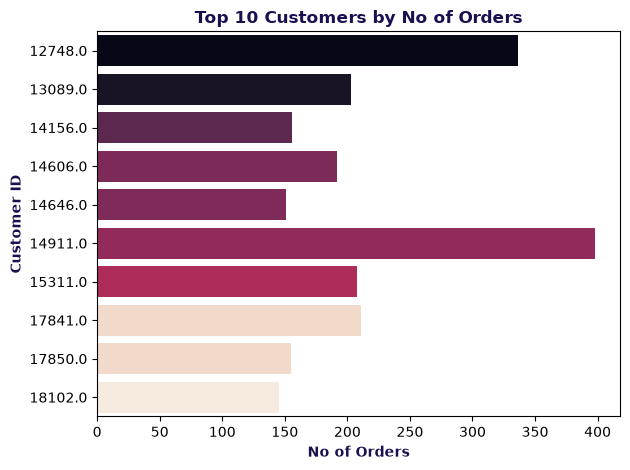

In [46]:
sns.barplot(
    x=customers_order.values,
    y=customers_order.index,
    orient="h",
    palette="rocket",
    hue=customers_order.index,
    legend=False
)

plt.title(
    "Top 10 Customers by No of Orders",
    color="#18104F",
    fontweight="bold"
)

plt.xlabel("No of Orders", color="#18104F", fontweight="bold")
plt.ylabel("Customer ID", color="#18104F", fontweight="bold")

plt.tight_layout()
plt.show()

## Top Countries by Number of Orders

This analysis identifies the countries with the highest number of orders.

It helps understand which geographical markets have the highest order activity, independent of the total revenue generated.


In [47]:
country_Invo=df.groupby("Country")["InvoiceNo"].value_counts()
country_Invo

Country      InvoiceNo
Australia    556917       138
             536009        99
             563614        97
             513987        87
             545475        82
                         ... 
Unspecified  C521020        1
             531209         1
             531212         1
             C532353        1
West Indies  520018        54
Name: count, Length: 48369, dtype: int64

In [48]:
co_In = country_Invo.groupby(level="Country").size().sort_values(ascending=False).head(10).reset_index()
co_In

,Country,count
0,United Kingdom,43850
1,Germany,1095
2,EIRE,806
3,France,746
4,Netherlands,249
5,Spain,188
6,Belgium,183
7,Sweden,129
8,Portugal,124
9,Switzerland,123


In [49]:
fig = px.bar(
    co_In,
    x="count",
    y="Country",
    orientation="h",
    text="count",
    title="Top 10 Countries by Number of Orders"
)

fig.update_traces(
    textposition="outside",
    marker_color="#662E5C",
    opacity=0.85
)

fig.update_layout(
    xaxis_title="Number of Orders",
    yaxis_title="Country",
    height=600,
    template="plotly_white"
)



fig.show()

## Monthly Order Volume

This analysis examines how the number of orders changes over time on a monthly basis.

It helps identify periods of higher or lower order activity and provides a different perspective from monthly revenue trends.


In [50]:
Mon_In=df.groupby("YearMonth")["InvoiceNo"].value_counts()
Mon_In

YearMonth  InvoiceNo
2009-12    490074       580
           491966       579
           490149       559
           491969       548
           490741       546
                       ... 
2011-12    581487         1
           581491         1
           C581499        1
           581566         1
           C581568        1
Name: count, Length: 48369, dtype: int64

In [51]:
Monthly_Invoice = Mon_In.groupby(level="YearMonth").size().reset_index()
Monthly_Invoice

,YearMonth,count
0,2009-12,2083
1,2010-01,1405
2,2010-02,1441
3,2010-03,2088
4,2010-04,1766
5,2010-05,1907
6,2010-06,2002
7,2010-07,1873
8,2010-08,1698
9,2010-09,2210


In [52]:
fig=px.line(Monthly_Invoice, x=Monthly_Invoice["YearMonth"], y=Monthly_Invoice["count"], markers=True)


fig.update_layout(
    title="Monthly Order Volume",
    title_font=dict(size=20, color="#18104F"),
    xaxis_title="Year-Month",
    yaxis_title="Number of Orders",
    height=550,
    template="plotly_white"
)

fig.update_traces(
    marker=dict(symbol="diamond", size=10, color="#AC7CE7"),
    line=dict(color="#5A189A", width=3)
)

fig.show()

## Revenue vs Quantity for Top Products

This analysis examines the relationship between the quantity sold and revenue generated by top-performing products.

It helps understand whether products with higher sales volume also contribute proportionally to revenue.


In [53]:
Qty_rev=df.groupby("Description")[["Quantity", "Revenue", "UnitPrice"]].agg({"Quantity": "sum",
    "Revenue": "sum",
    "UnitPrice": "mean"
}).sort_values(by="Revenue", ascending=False).head(10).reset_index()
Qty_rev

,Description,Quantity,Revenue,UnitPrice
0,REGENCY CAKESTAND 3 TIER,25028,314045.02,14.020578
1,DOTCOM POSTAGE,1412,309844.10,218.521946
2,WHITE HANGING HEART T-LIGHT HOLDER,91082,251781.63,3.129011
3,JUMBO BAG RED WHITE SPOTTY,95544,178400.52,2.321200
4,mailout,49585,172762.72,5.024676
5,PARTY BUNTING,27915,147079.73,5.709754
6,ASSORTED COLOUR BIRD ORNAMENT,79571,128550.42,1.857747
7,PAPER CHAIN KIT 50'S CHRISTMAS,34494,116298.59,3.364760
8,POSTAGE,5061,110430.41,32.959731
9,CHILLI LIGHTS,15696,79905.13,6.264888


In [54]:
fig = px.scatter(
    Qty_rev,
    x="Quantity",
    y="Revenue",
    size="UnitPrice",
    hover_name="Description",
    title="Revenue vs Quantity for Top Products",
    labels={
        "Quantity": "Quantity Sold",
        "Revenue": "Revenue",
        "UnitPrice": "Average Unit Price"
    },
    size_max=45,
    
    color="Description",
    color_discrete_sequence=[
    "#12143C",
    "#379A9E",
    "#E45756",
    "#673E3E",
    "#7B6D8D",
    "#D4A72C",
    "#4C78A8",
    "#59A14F",
    "#B07AA1",
    "#F28E2B"
]

)

fig.update_traces(
    opacity=0.75
)

fig.update_layout(
    height=600
    
)

fig.show()

## Top 10 Customers by Revenue

This analysis identifies the customers who generate the highest revenue.

It helps understand high-value customers and their contribution to overall business revenue.


In [55]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,Day,DayName,Hour,IsCancelled,YearMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40,2009,12,December,1,Tuesday,7,False,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00,2009,12,December,1,Tuesday,7,False,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00,2009,12,December,1,Tuesday,7,False,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80,2009,12,December,1,Tuesday,7,False,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00,2009,12,December,1,Tuesday,7,False,2009-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1027010,581587,22899,CHILDRENS APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011,12,December,9,Friday,12,False,2011-12
1027011,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,December,9,Friday,12,False,2011-12
1027012,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011,12,December,9,Friday,12,False,2011-12
1027013,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85,2011,12,December,9,Friday,12,False,2011-12


In [56]:
df.CustomerID.notna()

0          True
1          True
2          True
3          True
4          True
           ... 
1027010    True
1027011    True
1027012    True
1027013    True
1027014    True
Name: CustomerID, Length: 1027015, dtype: bool

In [57]:
exclude_cust_can=df[(df["IsCancelled"]==False) & ( df.CustomerID.notna()) ].groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False).head(10).reset_index()
exclude_cust_can

,CustomerID,Revenue
0,18102.0,580987.04
1,14646.0,528602.52
2,14156.0,313437.62
3,14911.0,291420.81
4,17450.0,244784.25
5,13694.0,195640.69
6,17511.0,172132.87
7,16446.0,168472.50
8,16684.0,147142.77
9,12415.0,144458.37


In [58]:
exclude_cust_can.shape

(10, 2)

In [59]:
exclude_cust_can.dtypes

CustomerID    float64
Revenue       float64
dtype: object

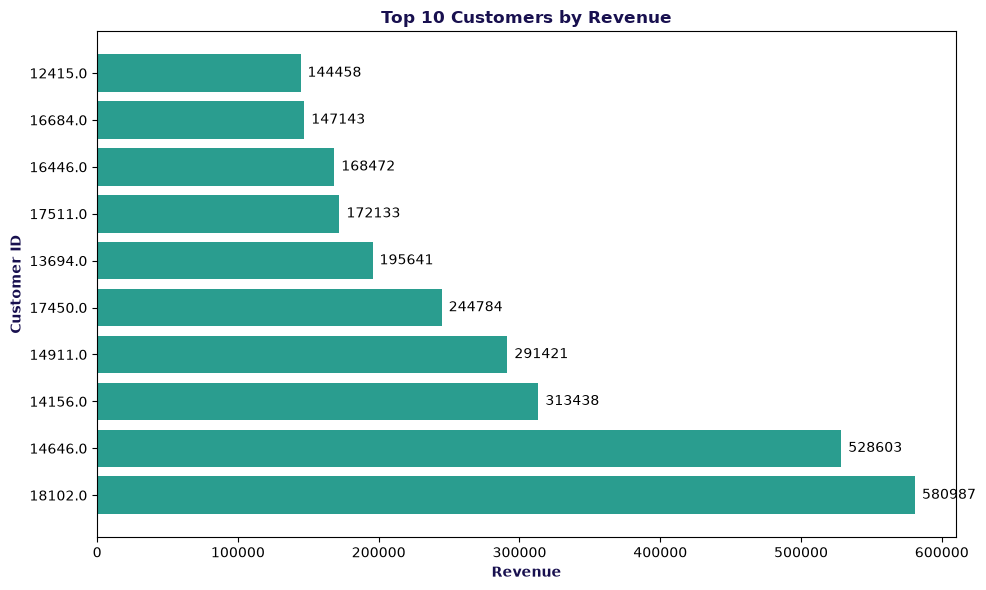

In [60]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    exclude_cust_can["CustomerID"].astype(str),
    exclude_cust_can["Revenue"],
    color="#2A9D8F"
)

plt.bar_label(bars, fmt="%.0f", padding=5)

plt.xlabel("Revenue",color="#18104F",fontweight="bold")
plt.ylabel("Customer ID",color="#18104F",fontweight="bold")
plt.title("Top 10 Customers by Revenue",color="#18104F",fontweight="bold")


plt.tight_layout()
plt.show()

## KPIs

The following Key Performance Indicators (KPIs) summarize the overall business performance of the e-commerce dataset.

These metrics provide a high-level view of revenue, orders, customers, products, and transaction cancellations.


## Average Order Value

This analysis calculates the average revenue generated per order.

It helps understand the typical value of an order and provides insight into overall purchasing value.

In [61]:
# KPI CARD

InvoiceNo_Reven=df.groupby("InvoiceNo")["Revenue"].sum()
avg_ord_value=InvoiceNo_Reven.mean()
avg_ord_value

np.float64(393.09594963716427)

In [62]:
total_re=df.Revenue.sum()
print("Total Revenue :" ,total_re)

Total Revenue : 19013657.988


In [63]:
total_ord=df.InvoiceNo.nunique()
print("Total Orders :" ,total_ord)

Total Orders : 48369


In [64]:
aov = total_re/total_ord
print("Average Order Value :",aov)

Average Order Value : 393.0959496371643


In [65]:
total_cust = df.CustomerID.dropna().nunique()
print("Total Customers :",total_cust)

Total Customers : 5939


In [66]:
total_prod=df.Description.nunique()
print("Total Products :", total_prod)

Total Products : 4734


In [67]:
total_transection = df.IsCancelled.count()
print("total Transection",total_transection)

total Transection 1027015


In [68]:
Cancellation_transection=df[(df["IsCancelled"]==True)].shape[0]
print("Cancellation transection",Cancellation_transection)

Cancellation transection 19104


In [69]:
cancell_rate=(Cancellation_transection/total_transection)*100 
print("Cancellation Rate",cancell_rate)

Cancellation Rate 1.8601480991027395


## Key Business Insights

* **Revenue Trend:** Revenue was not the same every month. Sales were generally higher during September to November, and the highest monthly revenue was recorded in **November 2011**, at around **1.46 million**.

* **Country Performance:** The **United Kingdom** generated the highest revenue, around **16.14 million**. This shows that the UK was the main market in this dataset.

* **Product Performance:** **REGENCY CAKESTAND 3 TIER** was the highest revenue-generating product, with revenue of around **314,045**. Some non-product entries such as postage also appeared among the top revenue entries.

* **Customer Performance:** Customer **18102** generated the highest revenue among the top customers, around **580,987**. This shows that some customers contributed much more revenue than others.

* **Cancellation Trend:** The cancellation rate decreased from **2.28% in 2009** to **1.73% in 2011**. This shows that the cancellation rate improved over the years.

* **Overall Performance:** The dataset contains **48,369 orders** and generated around **19.01 million** in revenue. The average order value was around **393.10**, with **5,939 customers** and **4,734 products**.
